# 10 — Rotulação das sessões de eventos (S002 a S006)

Transforma cada sessão gravada pelo firmware de coleta em janelas rotuladas para o treino e o teste (seção 3.3.1):

| Ramo | Janela | Rótulo |
|---|---|---|
| CNN | 1 s de áudio (98 × 40 log-mel) | **nível acústico** pelos registros: nível do evento nos tipos desbalanceamento, obstrução e combinado; 0 fora deles e no tipo térmico |
| LSTM | 30 passos de 10 s do BME280 (5 min) | **nível térmico** pela leitura do **termo-higrômetro de referência** no último passo (27, 32 e 35 °C) |
| Fusão | decisão a cada 10 s: janela do LSTM + 10 últimas janelas da CNN | **classe final** pela matriz da Figura 5 (nível térmico × nível acústico) |

Os rótulos não usam nenhuma predição dos modelos. São **descartadas**: as janelas de áudio a menos de `TRANSICAO_S` de uma marcação; as janelas do LSTM sem referência térmica ou com mudança de faixa nos últimos passos; as decisões em que as 10 janelas de áudio não têm o mesmo nível.

**Antes de rodar**

1. Rode o **notebook 08** em cada sessão (com `LINHA_DE_BASE = False` nas sessões de eventos) e resolva as pendências.
2. Em `dissertacao_tinyml/coleta/`, mantenha:
   * `sessoes.csv`: uma linha por sessão (`sessao,tipo_sessao,papel,inicio_real,offset_termo_s,fundo_inicio,fundo_fim`);
   * `planilha_eventos.csv`: uma linha por evento (`sessao,evento,tipo,nivel,fundo,...`), na ordem em que foram executados.
3. Em cada pasta de sessão de eventos, `termo.csv` com as leituras do termo-higrômetro (`horario,temp_ref,umid_ref`), obtidas do time-lapse do visor.
4. O `base.csv` do notebook 09 em `coleta/linha_de_base/`.

**Saídas** em `dissertacao_tinyml/coleta/rotulado/`: `<sessão>.npz`, `resumo_rotulos.csv` e uma figura por sessão.

In [1]:
# 1. Ambiente e caminhos
import os, json, numpy as np, pandas as pd, matplotlib.pyplot as plt
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/dissertacao_tinyml"
except ImportError:
    BASE = os.environ.get("BASE_TINYML", "dissertacao_tinyml")
CONJUNTO = os.environ.get("CONJUNTO_TINYML", "coleta_sim")   # "coleta_sim" = sessões sintéticas (notebook 07b) | "coleta" = dados do nó
CONJUNTO = "coleta_sim"
SIM = CONJUNTO != "coleta"
print("Conjunto de dados:", CONJUNTO)
DISS = f"{BASE}/dissertacao_cap9" + ("_sim" if SIM else ""); os.makedirs(DISS, exist_ok=True)   # figuras e tabelas que vão para o texto
COLETA = f"{BASE}/{CONJUNTO}"; SAIDA = f"{COLETA}/rotulado"; os.makedirs(SAIDA, exist_ok=True)
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
                     "font.size": 10, "axes.titlesize": 10.5, "savefig.dpi": 300, "savefig.bbox": "tight"})

Mounted at /content/drive
Conjunto de dados: coleta_sim


In [2]:
# 2. Parâmetros
TRANSICAO_S    = 30      # s descartados antes e depois de cada marcação "m" (áudio)
PASSOS_TRANS   = 3       # LSTM: descarta a janela se a faixa da referência muda nos últimos 3 passos (30 s)
MARGEM_BASE_C  = 1.0     # linha de base sem termo-higrômetro: Normal só se o BME280 ficar <= 27 - 1 °C na janela
SESSOES = pd.read_csv(f"{COLETA}/sessoes.csv", dtype=str).fillna("")
PLANILHA = pd.read_csv(f"{COLETA}/planilha_eventos.csv")
PLANILHA["tipo"] = PLANILHA.tipo.str.strip().str.lower()
assert PLANILHA.tipo.isin(["termico", "desbalanceamento", "obstrucao", "combinado"]).all(), "tipo inválido na planilha"
if SIM:   # proteção: com o conjunto sintético, só entram sessões geradas pelo 07b (SIMnnn)
    _fora = [s for s in SESSOES.sessao if not str(s).startswith("SIM")]
    assert not _fora, f"sessoes.csv de {CONJUNTO} contém sessões que não são do 07b: {_fora}"
print("Sessões lidas:", SESSOES.sessao.tolist())
print(SESSOES.to_string(index=False))

Sessões lidas: ['SIM001', 'SIM002', 'SIM003', 'SIM004', 'SIM005', 'SIM006']
sessao tipo_sessao     papel         inicio_real offset_termo_s        fundo_inicio           fundo_fim
SIM001  linha_base    treino 2026-01-05 08:00:00              0                                        
SIM002     eventos    treino 2026-01-06 08:00:00              0 2026-01-06 10:30:00 2026-01-06 14:10:00
SIM003     eventos    treino 2026-01-07 08:00:00              0 2026-01-07 10:00:00 2026-01-07 14:10:00
SIM004     eventos    treino 2026-01-08 08:00:00              0 2026-01-08 10:00:00 2026-01-08 14:10:00
SIM005     eventos validacao 2026-01-09 08:00:00              0 2026-01-09 10:30:00 2026-01-09 14:10:00
SIM006     eventos     teste 2026-01-10 08:00:00              0 2026-01-10 11:00:00 2026-01-10 14:10:00


In [3]:
# 3. Funções de leitura, espectrograma e rotulação (iguais às dos notebooks 08, 09, 11 e 12)
# ===== Leitura de uma sessão do firmware de coleta (Coleta_InSitu 1.0 / 1.1 / 1.2-diag) =====
import glob, os
import numpy as np
import pandas as pd
import soundfile as sf

FS_COLETA = 16000

def ler_info(pasta):
    """INFO.TXT: linhas chave=valor (início e, se a sessão foi encerrada, totais)."""
    info = {}
    caminho = os.path.join(pasta, "INFO.TXT")
    if os.path.exists(caminho):
        for linha in open(caminho, encoding="latin-1"):
            if "=" in linha:
                k, v = linha.strip().split("=", 1)
                info[k] = v
    return info

def ler_evt(pasta):
    return pd.read_csv(os.path.join(pasta, "EVT.CSV"))

def ler_amb(pasta):
    """AMB.CSV: t_ms, amostra, temp, umid, press, perdidas (campos vazios = BME280 sem leitura)."""
    a = pd.read_csv(os.path.join(pasta, "AMB.CSV"))
    a["h"] = a["amostra"] / FS_COLETA / 3600.0            # horas desde o início do áudio
    return a

def listar_wav(pasta):
    """Arquivos WAV em ordem, com o número de amostras pelo tamanho do arquivo e pelo cabeçalho.
    Cabeçalho com 0 amostras = arquivo não fechado (sessão desligada sem encerramento)."""
    linhas = []
    for arq in sorted(glob.glob(os.path.join(pasta, "A*.WAV")) + glob.glob(os.path.join(pasta, "A*.wav"))):
        tam = os.path.getsize(arq)
        with open(arq, "rb") as f:
            cab = f.read(44)
        dados_cab = int.from_bytes(cab[40:44], "little") if len(cab) == 44 else -1
        linhas.append({"arquivo": os.path.basename(arq), "caminho": arq, "bytes": tam,
                       "amostras_arquivo": max(0, (tam - 44) // 2), "amostras_cabecalho": max(0, dados_cab // 2),
                       "cabecalho_ok": dados_cab == tam - 44})
    w = pd.DataFrame(linhas)
    if len(w):
        w["inicio_amostra"] = w["amostras_arquivo"].cumsum() - w["amostras_arquivo"]
    return w

def ler_pcm(caminho, ini=0, n=None):
    """Lê amostras int16 do WAV pelo tamanho real do arquivo (funciona mesmo com cabeçalho não corrigido)."""
    with open(caminho, "rb") as f:
        f.seek(44 + 2 * ini)
        dados = f.read(-1 if n is None else 2 * n)
    return np.frombuffer(dados[: len(dados) // 2 * 2], dtype="<i2")

def serie_10s(amb):
    """Média das leituras em intervalos de 10 s do áudio (5 leituras de 2 s), como no firmware de inferência."""
    a = amb.dropna(subset=["temp", "umid", "press"]).copy()
    a["bloco"] = (a["amostra"] // (10 * FS_COLETA)).astype(int)
    s = a.groupby("bloco")[["temp", "umid", "press"]].mean()
    s = s.reindex(range(s.index.min(), s.index.max() + 1))   # blocos sem leitura ficam NaN
    s["h"] = s.index * 10 / 3600.0
    return s


# ===== Espectrograma log-mel idêntico ao do firmware (core_mimii do notebook 01 e espectro_mel.h) =====
FS, JANELA, FRAME, HOP, NFFT, N_MEL, FMIN, FMAX, EPS = 16000, 16000, 400, 160, 512, 40, 20.0, 8000.0, 1e-6
N_FRAMES = 1 + (JANELA - FRAME) // HOP                       # 98
HANN = (0.5 - 0.5 * np.cos(2 * np.pi * np.arange(FRAME) / FRAME)).astype(np.float32)
def _mel(f): return 2595.0 * np.log10(1.0 + f / 700.0)
def _hz(m): return 700.0 * (10 ** (m / 2595.0) - 1.0)
def banco_mel():
    freqs = np.arange(NFFT // 2 + 1) * FS / NFFT
    p = _hz(np.linspace(_mel(FMIN), _mel(FMAX), N_MEL + 2))
    B = np.zeros((N_MEL, NFFT // 2 + 1), np.float32)
    for m in range(N_MEL):
        B[m] = np.maximum(0, np.minimum((freqs - p[m]) / (p[m + 1] - p[m]), (p[m + 2] - freqs) / (p[m + 2] - p[m + 1])))
    return B
BANCO = banco_mel()
IDX = np.arange(FRAME)[None, :] + HOP * np.arange(N_FRAMES)[:, None]

def log_mel_lote(x):
    """x: (n, 16000) float32 em [-1, 1] -> (n, 98, 40), igual a core_mimii.log_mel janela a janela."""
    q = x[:, IDX] * HANN                                       # (n, 98, 400)
    e = np.fft.rfft(q, n=NFFT, axis=2)
    pot = (e.real ** 2 + e.imag ** 2).astype(np.float32)
    return np.log(pot @ BANCO.T + EPS).astype(np.float32)

def janelas_da_sessao(wav, ini_j=0, fim_j=None, passo=1, lote=600):
    """Gera (índices globais das janelas, log-mel (n, 98, 40)) para as janelas de 1 s em [ini_j, fim_j),
    lendo cada WAV uma única vez. Uma janela pode cruzar a fronteira entre dois arquivos."""
    total = int(wav.amostras_arquivo.sum()) // JANELA
    fim_j = total if fim_j is None else min(fim_j, total)
    resto, j = np.zeros(0, np.int16), 0
    for _, w in wav.iterrows():
        fim_arq = int(w.inicio_amostra + w.amostras_arquivo)
        if fim_arq <= ini_j * JANELA and len(resto) == 0 and fim_arq % JANELA == 0:
            j = fim_arq // JANELA; continue                    # arquivo inteiro antes do trecho pedido
        x = np.concatenate([resto, ler_pcm(w.caminho)])
        n = len(x) // JANELA
        js = np.arange(j, j + n)
        loc = np.where((js >= ini_j) & (js < fim_j) & ((js - ini_j) % passo == 0))[0]
        for k in range(0, len(loc), lote):
            l = loc[k:k + lote]
            bl = np.stack([x[i * JANELA:(i + 1) * JANELA] for i in l]).astype(np.float32) / 32768.0
            yield js[l], log_mel_lote(bl)
        resto, j = x[n * JANELA:], j + n
        if j >= fim_j: break


# ===== Rotulação das sessões de eventos (seção 3.3.1 e Figura 5) =====
TIPOS = ["termico", "desbalanceamento", "obstrucao", "combinado"]
ACUSTICOS = {"desbalanceamento", "obstrucao", "combinado"}     # o tipo térmico não altera o nível acústico
TERMICOS = {"termico", "combinado"}
NOMES_CLASSE = ["Normal", "Atenção", "Crítico", "Falha"]

def classe_termica(t):
    t = np.asarray(t, dtype=float)
    return np.select([t > 35.0, t > 32.0, t > 27.0], [3, 2, 1], 0)

def classe_fusao_regra(nt, na):
    """Figura 5: prevalece o mais severo; térmico 2 com acústico >= 1 vira Falha; nível 3 em qualquer ramo = Falha."""
    nt, na = np.asarray(nt), np.asarray(na)
    c = np.maximum(nt, na)
    c = np.where((nt == 2) & (na >= 1), 3, c)
    return np.where((nt == 3) | (na == 3), 3, c).astype(int)

def eventos_da_sessao(evt, planilha, sessao):
    """Junta os pares início/fim do EVT.CSV com a planilha (tipo, nível, fundo) pelo número do evento."""
    e = evt[evt.evento > 0]
    ini = e[e.tipo == "inicio"].set_index("evento").amostra
    fim = e[e.tipo == "fim"].set_index("evento").amostra
    ev = pd.DataFrame({"amostra_ini": ini, "amostra_fim": fim}).reset_index()
    p = planilha[planilha.sessao == sessao].copy()
    problemas = []
    if ev.amostra_fim.isna().any():
        problemas.append(f"eventos sem fim no EVT.CSV: {ev[ev.amostra_fim.isna()].evento.tolist()}")
    if len(ev) != len(p):
        problemas.append(f"EVT.CSV tem {len(ev)} eventos e a planilha tem {len(p)} para {sessao}")
    ev = ev.merge(p[["evento", "tipo", "nivel", "fundo"]], on="evento", how="left")
    if ev.tipo.isna().any():
        problemas.append(f"eventos sem linha na planilha: {ev[ev.tipo.isna()].evento.tolist()}")
    return ev, problemas

def rotulos_acusticos(n_jan, ev, fs, transicao_s):
    """Nível acústico de cada janela de 1 s: nível do evento (tipos acústicos) ou 0; -1 = janela descartada
    por estar a menos de transicao_s de uma marcação. Também devolve o número do evento de cada janela (0 = fora)."""
    ini = np.arange(n_jan) * fs; fim = ini + fs
    y = np.zeros(n_jan, int); evid = np.zeros(n_jan, int)
    marg = int(transicao_s * fs)
    for _, e in ev.iterrows():
        a, b = int(e.amostra_ini), int(e.amostra_fim)
        dentro = (ini >= a) & (fim <= b)
        evid[dentro] = e.evento
        if e.tipo in ACUSTICOS: y[dentro] = int(e.nivel)
        for m in (a, b):                                   # janelas perto de uma marcação
            y[(fim > m - marg) & (ini < m + marg)] = -1
    return y, evid

def referencia_10s(termo, inicio_real, blocos, offset_s=0.0, max_lacuna_s=60):
    """Temperatura do termo-higrômetro interpolada na grade de 10 s do áudio (NaN onde não há referência)."""
    if termo is None or not len(termo):
        return np.full(len(blocos), np.nan)
    s = (pd.to_datetime(termo.horario) - pd.Timestamp(inicio_real)).dt.total_seconds().values + offset_s
    t = termo.temp_ref.values.astype(float)
    ordem = np.argsort(s); s, t = s[ordem], t[ordem]
    grade = np.asarray(blocos) * 10.0 + 5.0                # centro de cada bloco de 10 s do áudio
    ref = np.interp(grade, s, t, left=np.nan, right=np.nan)
    pos = np.searchsorted(s, grade)
    viz = np.minimum(np.abs(grade - s[np.clip(pos - 1, 0, len(s) - 1)]), np.abs(s[np.clip(pos, 0, len(s) - 1)] - grade))
    ref[viz > max_lacuna_s] = np.nan                        # longe de qualquer leitura: sem referência
    return ref


In [4]:
# 4. Rotulação de uma sessão
def rotular(sx):
    sessao = sx.sessao; pasta = f"{COLETA}/{sessao}"
    info, evt, amb, wav = ler_info(pasta), ler_evt(pasta), ler_amb(pasta), listar_wav(pasta)
    assert int(info.get("ganho_pdm", 20)) == 20, f"{sessao}: ganho diferente de 20"
    eventos = sx.tipo_sessao.strip().lower() == "eventos"
    if eventos:
        ev, prob = eventos_da_sessao(evt, PLANILHA, sessao)
        if prob: raise SystemExit(f"{sessao}: " + "; ".join(prob))
    else:
        ev = pd.DataFrame(columns=["evento", "amostra_ini", "amostra_fim", "tipo", "nivel", "fundo"])
        if (evt.evento > 0).any(): print(f"Atenção: {sessao} é de linha de base mas tem eventos marcados")
    n_jan = int(wav.amostras_arquivo.sum()) // FS
    ya, evid = rotulos_acusticos(n_jan, ev, FS, TRANSICAO_S)

    # Fundo MIMII por janela (metadado; não é rótulo)
    fundo = np.zeros(n_jan, bool)
    if sx.fundo_inicio and sx.inicio_real:
        a = (pd.Timestamp(sx.fundo_inicio) - pd.Timestamp(sx.inicio_real)).total_seconds()
        b = (pd.Timestamp(sx.fundo_fim) - pd.Timestamp(sx.inicio_real)).total_seconds() if sx.fundo_fim else n_jan
        fundo[int(max(0, a)):int(min(n_jan, b))] = True

    # Espectrogramas de todas as janelas (float16, sem normalização: a linha de base é aplicada no notebook 11)
    Xc = np.zeros((n_jan, N_FRAMES, N_MEL), np.float16)
    for js, lm in janelas_da_sessao(wav):
        Xc[js] = lm.astype(np.float16)

    # Ramo ambiental: série de 10 s (entrada, BME280) e referência térmica (rótulo, termo-higrômetro)
    s10 = serie_10s(amb); s10 = s10[s10.index >= 0]
    v = s10[["temp", "umid", "press"]].to_numpy(np.float32)
    termo = pd.read_csv(f"{pasta}/termo.csv") if os.path.exists(f"{pasta}/termo.csv") else None
    off = float(sx.offset_termo_s or 0)
    ref = referencia_10s(termo, sx.inicio_real, s10.index.values, off) if (termo is not None and sx.inicio_real) else np.full(len(v), np.nan)
    blocos0 = int(s10.index[0])
    Xl, yl, bl = [], [], []
    for i in range(len(v) - 29):
        w = v[i:i + 30]
        if np.isnan(w).any(): continue
        r = ref[i:i + 30]
        if not np.isnan(r[-1]):
            faixas = classe_termica(r[-PASSOS_TRANS:])
            if np.isnan(r[-PASSOS_TRANS:]).any() or len(set(faixas)) > 1: continue
            y = int(faixas[-1])
        elif not eventos and w[:, 0].max() <= 27.0 - MARGEM_BASE_C:
            y = 0                                          # linha de base sem referência: Normal com margem
        else:
            continue
        Xl.append(w); yl.append(y); bl.append(blocos0 + i + 29)   # bloco de 10 s do último passo
    Xl = np.array(Xl, np.float32).reshape(-1, 30, 3); yl = np.array(yl, int); bl = np.array(bl, int)

    # Decisões a cada 10 s: janela do LSTM terminando no bloco b + janelas de áudio do mesmo bloco
    dec = []
    for k, b in enumerate(bl):
        js = np.arange(b * 10, b * 10 + 10)
        if js[-1] >= n_jan: continue
        a = ya[js]
        if (a < 0).any() or len(set(a)) > 1: continue
        dec.append((k, js[-1], yl[k], int(a[0]), int(classe_fusao_regra(yl[k], a[0])), int(evid[js[-1]])))
    dec = np.array(dec, int).reshape(-1, 6)

    np.savez_compressed(f"{SAIDA}/{sessao}.npz", Xc=Xc, ya=ya, evid=evid, fundo=fundo, Xl=Xl, yl=yl, bl=bl,
                        dec_l=dec[:, 0], dec_j=dec[:, 1], dec_yt=dec[:, 2], dec_ya=dec[:, 3], dec_y=dec[:, 4],
                        dec_ev=dec[:, 5], temp_ref=ref, temp_bme=v[:, 0], blocos10=s10.index.values)
    ev.to_csv(f"{SAIDA}/{sessao}_eventos.csv", index=False)
    return {"sessao": sessao, "papel": sx.papel, "janelas_audio": n_jan, "audio_descartadas": int((ya < 0).sum()),
            **{f"audio_nivel{c}": int((ya == c).sum()) for c in range(4)},
            "janelas_lstm": len(yl), **{f"lstm_classe{c}": int((yl == c).sum()) for c in range(4)},
            "decisoes": len(dec), **{f"decisao_{NOMES_CLASSE[c]}": int((dec[:, 4] == c).sum()) for c in range(4)},
            "referencia_termica": termo is not None}, ev, ref, v, ya, s10.index.values

def figura(sessao, ev, ref, v, ya, blocos):
    h10 = blocos * 10 / 3600
    fig, ax = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True, constrained_layout=True)
    ax[0].plot(h10, v[:, 0], lw=0.8, color="C3", label="BME280 (entrada)")
    ax[0].plot(h10, ref, lw=1.2, color="k", label="Termo-higrômetro (rótulo)")
    for L in (27, 32, 35): ax[0].axhline(L, color="0.6", ls="--", lw=0.7)
    cores = {"termico": "C3", "desbalanceamento": "C0", "obstrucao": "C2", "combinado": "C4"}
    for _, e in ev.iterrows():
        for a in ax: a.axvspan(e.amostra_ini / FS / 3600, e.amostra_fim / FS / 3600, color=cores.get(e.tipo, "0.5"), alpha=0.12, lw=0)
        ax[0].text(e.amostra_ini / FS / 3600, ax[0].get_ylim()[1], f"{e.tipo[:4]} {int(e.nivel)}", fontsize=6, va="top")
    ax[1].plot(np.arange(len(ya)) / 3600, np.where(ya < 0, np.nan, ya), lw=0.8, color="0.2")
    ax[1].set_yticks([0, 1, 2, 3]); ax[1].set_ylabel("Nível acústico (rótulo)")
    ax[0].set_ylabel("Temperatura (°C)"); ax[0].legend(fontsize=7, loc="upper left")
    ax[1].set_xlabel("Horas desde o início da gravação")
    fig.suptitle(f"Sessão {sessao}: rótulos", fontsize=11)
    plt.savefig(f"{SAIDA}/Figura_rotulos_{sessao}.png"); plt.show()

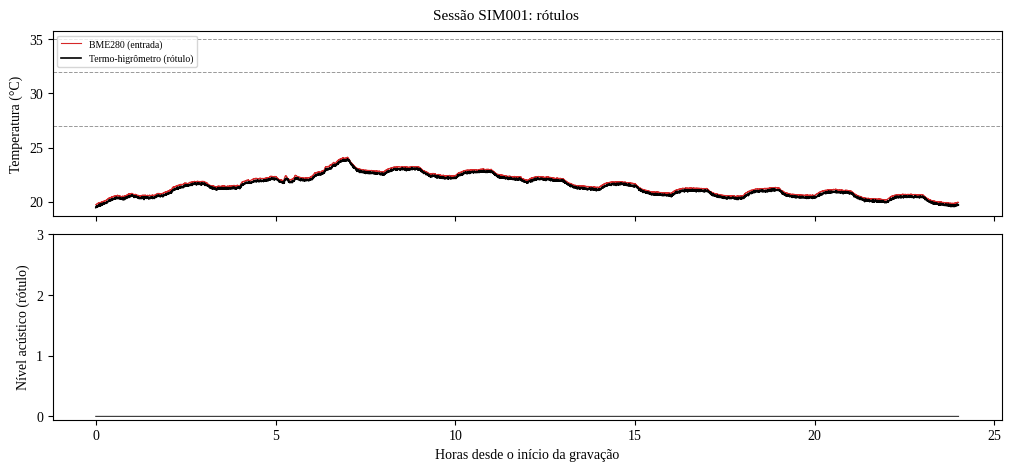

{"sessao": "SIM001", "papel": "treino", "janelas_audio": 86400, "audio_descartadas": 0, "audio_nivel0": 86400, "audio_nivel1": 0, "audio_nivel2": 0, "audio_nivel3": 0, "janelas_lstm": 8611, "lstm_classe0": 8611, "lstm_classe1": 0, "lstm_classe2": 0, "lstm_classe3": 0, "decisoes": 8611, "decisao_Normal": 8611, "decisao_Atenção": 0, "decisao_Crítico": 0, "decisao_Falha": 0, "referencia_termica": true}


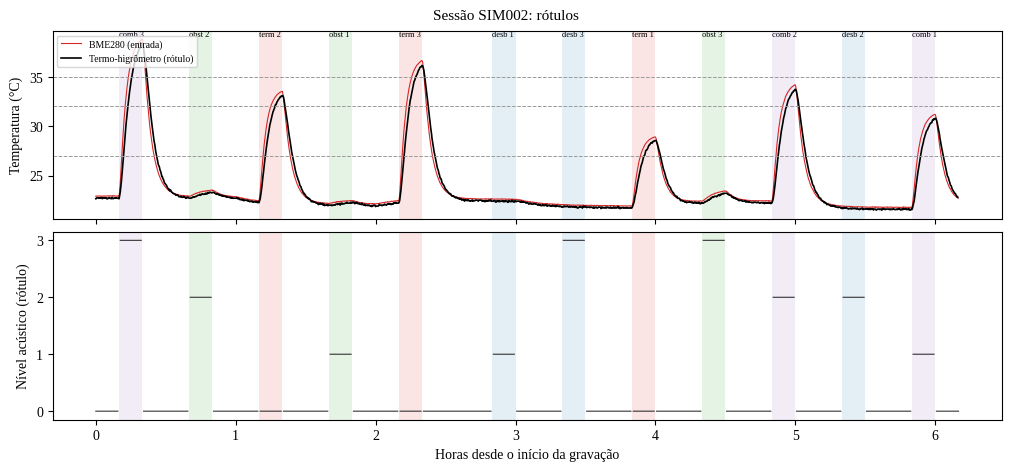

{"sessao": "SIM002", "papel": "treino", "janelas_audio": 22200, "audio_descartadas": 1440, "audio_nivel0": 15900, "audio_nivel1": 1620, "audio_nivel2": 1620, "audio_nivel3": 1620, "janelas_lstm": 2142, "lstm_classe0": 1774, "lstm_classe1": 222, "lstm_classe2": 88, "lstm_classe3": 58, "decisoes": 1998, "decisao_Normal": 1300, "decisao_Atenção": 309, "decisao_Crítico": 192, "decisao_Falha": 197, "referencia_termica": true}


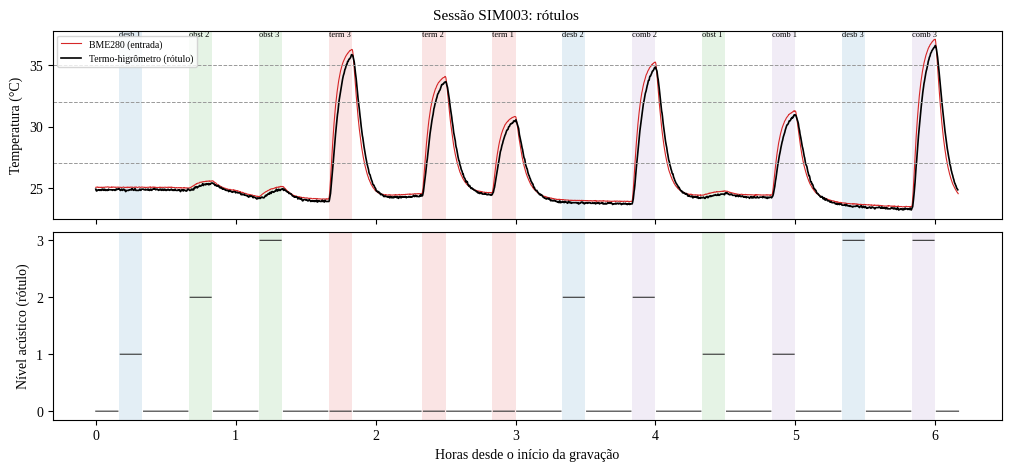

{"sessao": "SIM003", "papel": "treino", "janelas_audio": 22200, "audio_descartadas": 1440, "audio_nivel0": 15900, "audio_nivel1": 1620, "audio_nivel2": 1620, "audio_nivel3": 1620, "janelas_lstm": 2142, "lstm_classe0": 1696, "lstm_classe1": 282, "lstm_classe2": 119, "lstm_classe3": 45, "decisoes": 1998, "decisao_Normal": 1232, "decisao_Atenção": 363, "decisao_Crítico": 204, "decisao_Falha": 199, "referencia_termica": true}


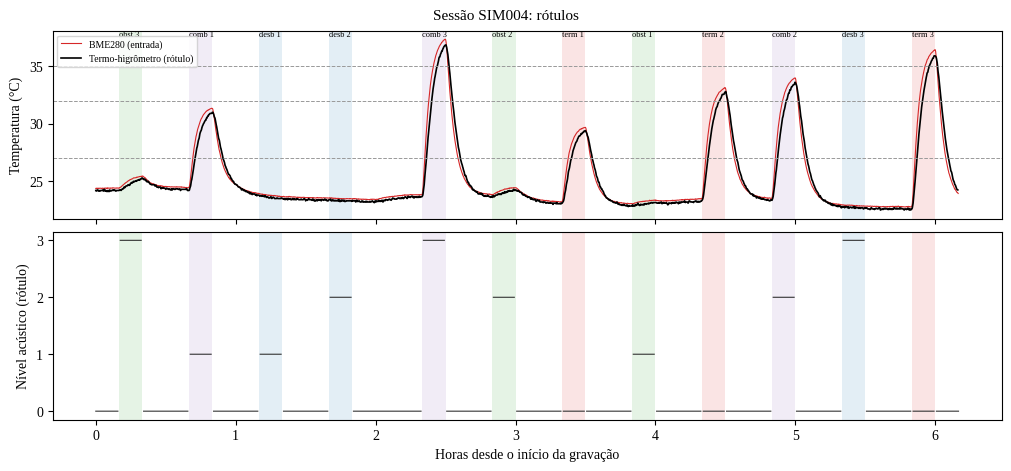

{"sessao": "SIM004", "papel": "treino", "janelas_audio": 22200, "audio_descartadas": 1440, "audio_nivel0": 15900, "audio_nivel1": 1620, "audio_nivel2": 1620, "audio_nivel3": 1620, "janelas_lstm": 2142, "lstm_classe0": 1738, "lstm_classe1": 266, "lstm_classe2": 91, "lstm_classe3": 47, "decisoes": 1998, "decisao_Normal": 1273, "decisao_Atenção": 343, "decisao_Crítico": 189, "decisao_Falha": 193, "referencia_termica": true}


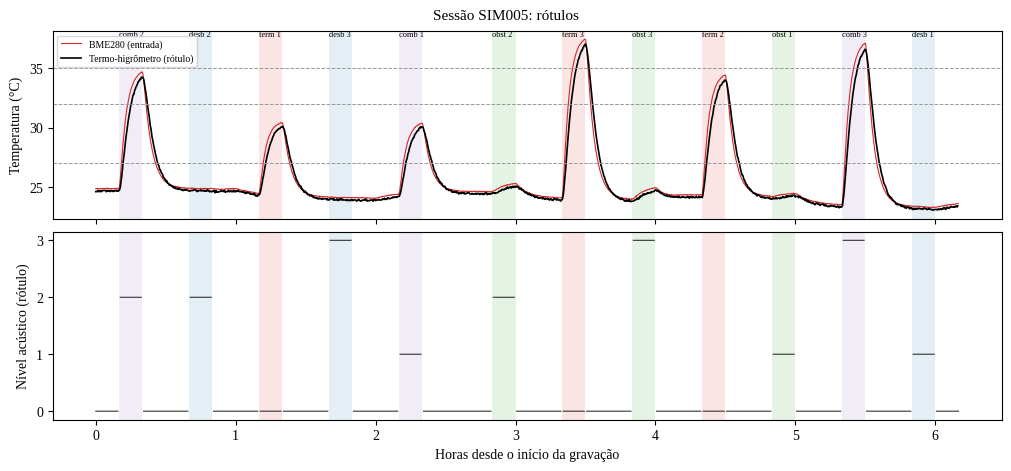

{"sessao": "SIM005", "papel": "validacao", "janelas_audio": 22200, "audio_descartadas": 1440, "audio_nivel0": 15900, "audio_nivel1": 1620, "audio_nivel2": 1620, "audio_nivel3": 1620, "janelas_lstm": 2142, "lstm_classe0": 1699, "lstm_classe1": 273, "lstm_classe2": 114, "lstm_classe3": 56, "decisoes": 1998, "decisao_Normal": 1235, "decisao_Atenção": 353, "decisao_Crítico": 201, "decisao_Falha": 209, "referencia_termica": true}


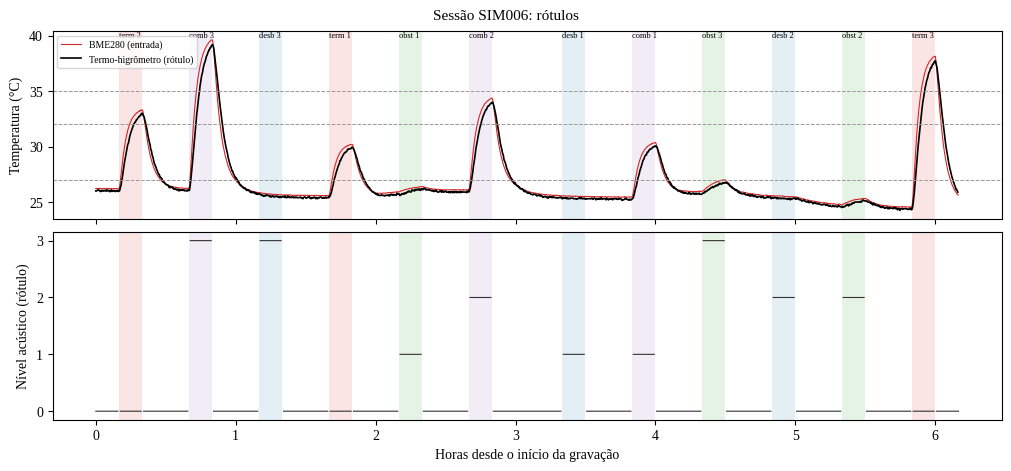

{"sessao": "SIM006", "papel": "teste", "janelas_audio": 22200, "audio_descartadas": 1440, "audio_nivel0": 15900, "audio_nivel1": 1620, "audio_nivel2": 1620, "audio_nivel3": 1620, "janelas_lstm": 2142, "lstm_classe0": 1597, "lstm_classe1": 361, "lstm_classe2": 101, "lstm_classe3": 83, "decisoes": 1998, "decisao_Normal": 1146, "decisao_Atenção": 436, "decisao_Crítico": 193, "decisao_Falha": 223, "referencia_termica": true}


,sessao,papel,janelas_audio,audio_descartadas,audio_nivel0,audio_nivel1,audio_nivel2,audio_nivel3,janelas_lstm,lstm_classe0,lstm_classe1,lstm_classe2,lstm_classe3,decisoes,decisao_Normal,decisao_Atenção,decisao_Crítico,decisao_Falha,referencia_termica
0,SIM001,treino,86400,0,86400,0,0,0,8611,8611,0,0,0,8611,8611,0,0,0,True
1,SIM002,treino,22200,1440,15900,1620,1620,1620,2142,1774,222,88,58,1998,1300,309,192,197,True
2,SIM003,treino,22200,1440,15900,1620,1620,1620,2142,1696,282,119,45,1998,1232,363,204,199,True
3,SIM004,treino,22200,1440,15900,1620,1620,1620,2142,1738,266,91,47,1998,1273,343,189,193,True
4,SIM005,validacao,22200,1440,15900,1620,1620,1620,2142,1699,273,114,56,1998,1235,353,201,209,True
5,SIM006,teste,22200,1440,15900,1620,1620,1620,2142,1597,361,101,83,1998,1146,436,193,223,True


In [5]:
# 5. Executa para todas as sessões do sessoes.csv
resumo = []
for _, sx in SESSOES.iterrows():
    if not os.path.isdir(f"{COLETA}/{sx.sessao}"):
        print("Pasta ausente, pulada:", sx.sessao); continue
    r, ev, ref, v, ya, blocos = rotular(sx)
    resumo.append(r); figura(sx.sessao, ev, ref, v, ya, blocos)
    print(json.dumps(r, ensure_ascii=False))
resumo = pd.DataFrame(resumo); resumo.to_csv(f"{SAIDA}/resumo_rotulos.csv", index=False)
resumo

In [6]:
# 6. Conferência: cada papel (treino, validação, teste) precisa ter todas as classes
por_papel = resumo.groupby("papel")[[f"decisao_{c}" for c in NOMES_CLASSE]].sum()
print(por_papel)
faltam = [(p, c) for p in por_papel.index for c in NOMES_CLASSE if por_papel.loc[p, f"decisao_{c}"] == 0]
for p, c in faltam: print(f"ATENÇÃO: papel '{p}' sem decisões da classe {c}")
if not faltam: print("Todas as classes presentes em treino, validação e teste.")

           decisao_Normal  decisao_Atenção  decisao_Crítico  decisao_Falha
papel                                                                     
teste                1146              436              193            223
treino              12416             1015              585            589
validacao            1235              353              201            209
Todas as classes presentes em treino, validação e teste.


### ➜ DISSERTAÇÃO — Figura da seção 9.1

Exemplo de sessão de eventos: (a) temperatura do BME280 (entrada) e do termo-higrômetro (rótulo) com os eventos sombreados por tipo; (b) nível acústico rotulado. Sem título dentro da imagem (padrão APA).

Título sugerido: *Exemplo de sessão de avaliação com os eventos e os rótulos térmico e acústico*. Nota: sessão sintética (seção 9.1); faixas tracejadas em 27, 32 e 35 °C.

Arquivo: `Figura_9_1_sessao_exemplo.png / .svg` na pasta `dissertacao_cap9_sim/` (ou `dissertacao_cap9/` com dados do nó). No Word: rótulo com `SEQ Figura`, título em itálico e a nota indicada abaixo.

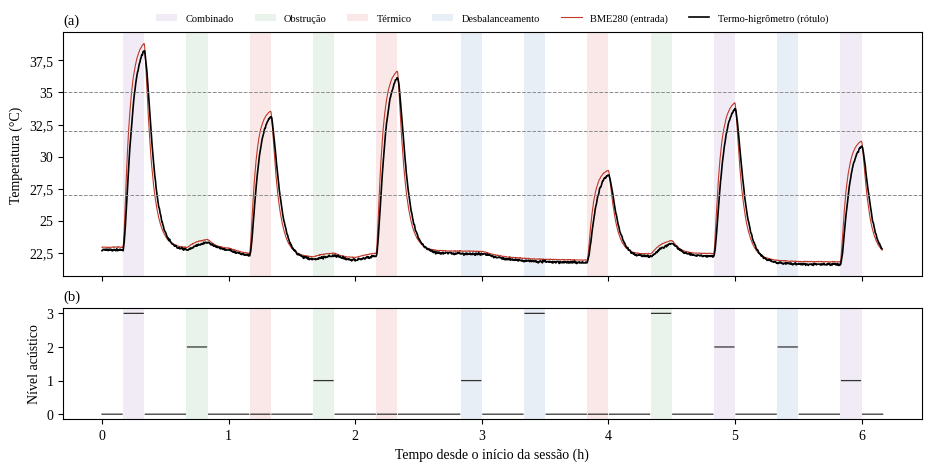

Sessão usada: SIM002


In [7]:
# 7. Figura para a dissertação: uma sessão de eventos, no padrão das figuras do texto
SESSAO_FIGURA = SESSOES[SESSOES.tipo_sessao == "eventos"].sessao.iloc[0]      # troque se quiser outra sessão
d = np.load(f"{SAIDA}/{SESSAO_FIGURA}.npz"); ev = pd.read_csv(f"{SAIDA}/{SESSAO_FIGURA}_eventos.csv")
h10 = d["blocos10"] * 10 / 3600
virgula = plt.FuncFormatter(lambda v, _: f"{v:g}".replace(".", ","))
fig, ax = plt.subplots(2, 1, figsize=(9.2, 4.6), sharex=True, constrained_layout=True, gridspec_kw={"height_ratios": [2.2, 1]})
NOME = {"termico": "Térmico", "desbalanceamento": "Desbalanceamento", "obstrucao": "Obstrução", "combinado": "Combinado"}
cores = {"termico": "#d9534f", "desbalanceamento": "#4a7fb5", "obstrucao": "#5aa469", "combinado": "#8e6bb8"}
vistos = set()
for _, e in ev.iterrows():
    for a in ax:
        a.axvspan(e.amostra_ini / FS / 3600, e.amostra_fim / FS / 3600, color=cores[e.tipo], alpha=0.13, lw=0,
                  label=NOME[e.tipo] if (a is ax[0] and e.tipo not in vistos) else None)
    vistos.add(e.tipo)
ax[0].plot(h10, d["temp_bme"], lw=0.8, color="#c0392b", label="BME280 (entrada)")
ax[0].plot(h10, d["temp_ref"], lw=1.2, color="k", label="Termo-higrômetro (rótulo)")
for L in (27, 32, 35): ax[0].axhline(L, color="0.55", ls="--", lw=0.7)
ax[0].set_ylabel("Temperatura (°C)"); ax[0].set_title("(a)", loc="left")
ax[0].legend(fontsize=7.5, ncol=6, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
ya = d["ya"].astype(float); ya[ya < 0] = np.nan
ax[1].step(np.arange(len(ya)) / 3600, ya, where="post", lw=0.9, color="0.2")
ax[1].set_yticks([0, 1, 2, 3]); ax[1].set_ylabel("Nível acústico"); ax[1].set_title("(b)", loc="left")
ax[1].set_xlabel("Tempo desde o início da sessão (h)")
for a in ax: a.xaxis.set_major_formatter(virgula); a.yaxis.set_major_formatter(virgula)
for ext in ["png", "svg"]: plt.savefig(f"{DISS}/Figura_9_1_sessao_exemplo.{ext}")
plt.show(); print("Sessão usada:", SESSAO_FIGURA)

## Interpretação

* **Classe final ≠ tipo de evento.** Um evento térmico de nível 1 só vira Atenção quando o termo-higrômetro passa de 27 °C; antes disso as janelas ficam Normal. Por isso a contagem de decisões por classe (célula 5) é a que vale para o treino.
* **Sem `termo.csv`**, a sessão de eventos não gera janelas do LSTM nem decisões: a referência térmica é obrigatória (seção 3.3.1).
* **Linha de base sem termo-higrômetro**: as janelas do LSTM entram como Normal só se o BME280 ficou pelo menos `MARGEM_BASE_C` abaixo de 27 °C. Declarar essa regra na dissertação se ela for usada.